*Note: This lab will be due after the exam, on October 14 @ midnight.*

## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<img src="./src/Intraaortic_Balloon.png" width=600>

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

### Answer:
We have almost the same number of patients in both groups, but the number of survivors are different from each other. The estimated ATE is `-0.01` that means conservative group(B) has a survival rate about 1 percentage point higher than invasive group(A). Based on this observed data, I would prefer conservative treatment, although teh difference is very small, so in order to undrestand whether there is a meaning ful evidance that one treatment is better than other, we have to check the confidance interval.

In [3]:
df = pd.read_csv('../data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  290   99
Invasive      293   95 

Estimated ATE:  -0.01


In [4]:
df.head()

,Survived,Group
0,1.0,Invasive
1,1.0,Invasive
2,1.0,Invasive
3,1.0,Invasive
4,1.0,Invasive


**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [5]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

In [7]:

print("Bootstrap A mean:", np.mean(outcome_a))
print("Bootstrap B mean:", np.mean(outcome_b))
print("Bootstrap ATE mean:", np.mean(ate))

print("Number of repetitions:", len(ate))


Bootstrap A mean: 0.24472628865979382
Bootstrap B mean: 0.2545501285347044
Bootstrap ATE mean: -0.009823839874910556
Number of repetitions: 10000


**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

### Answer:
In KDE graph, for instance, the bootstrap survival rate for conservative groups are concentrated around `25.5%`, and invasive groups concentrated around `24.5%`, but we can still see lots of overlaps between these groups from bootstrap distribution which means the differnce is small compare to sampling variability. 
Also, in ECDF graph we shows conservatiove has some how higher survival rate because it moved a little bit to the right side. So, Both graphs (KDE and ECDF), shows that conservative group has higher estimated survival rate compare to invasive group, but  we still can't say that one treatment is significantly better than other.


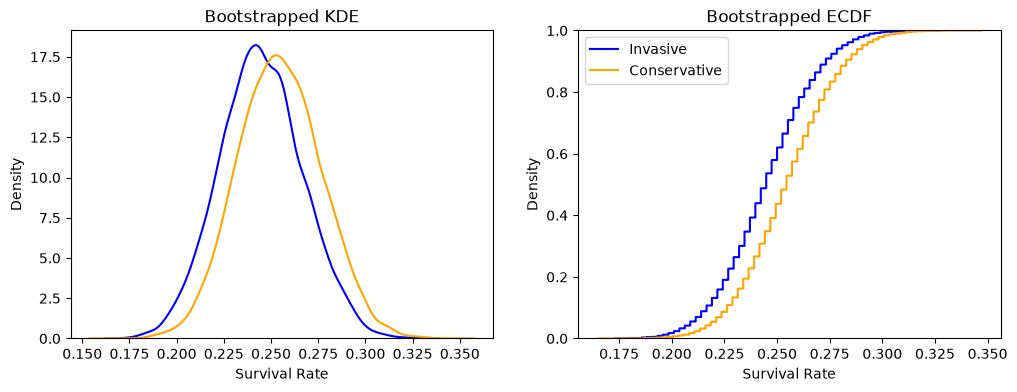

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

**4.** Make a plot of the KDE and ECDF for the ATE. 

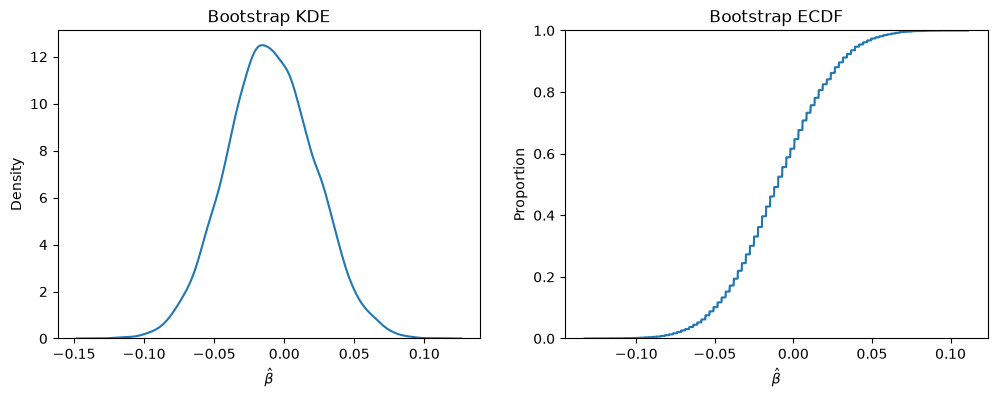

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

### Answer: 
All confidance interval (90% ,95%, 99%) for ATE has zeros ([-0.06110036  0.04181353],[-0.07140302  0.0521031 ], [-0.08940453  0.07013095]), so this indicates that we fail to reject the null hypothesis. 
- NULL Hypothesis id : $H_0:ATE=0$

Although we ourt actual ATE was `-0.01`, but the confidance interval tell us that difference is not statistically significant, so we don;t have enough evidance to determine one treatement is better than other.  

In [9]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06110036  0.04181353]
95% CI: [-0.07140302  0.0521031 ]
99% CI: [-0.08940453  0.07013095]


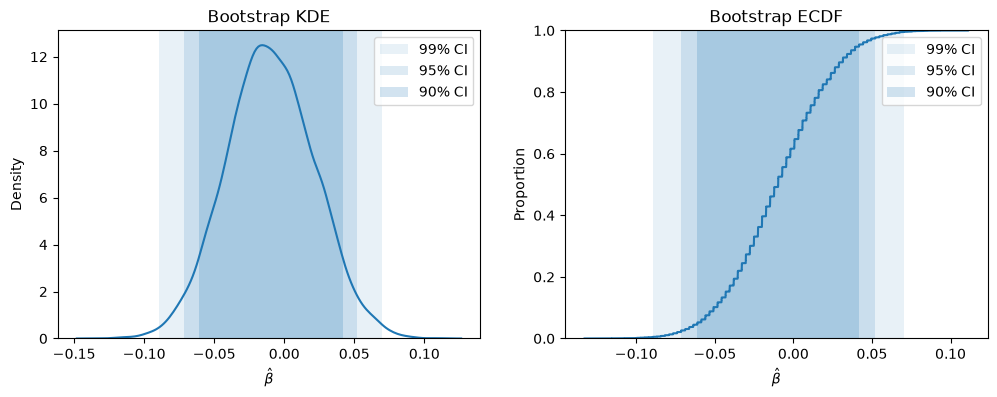

In [10]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

After analyzing and calculating ATE with the observed data and bootstrapping, I found out that the invasive treatment doesn't show any clear benefit in survival rate compared to the conservative method. The `ATE` was about -0.01 which indicates that the invasive method has a 1 percentage point lower survival rate compared to the conservative method. In addition, we checked the `90%, 95%, and 99%` confidence intervals, all of which include `zero` in their ranges. So, we fail to reject the null hypothesis, and the observed difference could be due to sampling variability. As a result, we  don't have enough evidence to show that inserting balloons into hearts can increase the survival rate. 

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [11]:
df_diabetes = pd.read_csv('../data/diabetes.csv')

df_diabetes.head()


,Unnamed: 0,treatment,outcome
0,1,met,success
1,2,rosi,failure
2,3,rosi,success
3,4,lifestyle,success
4,5,met,success


In [12]:

print(df_diabetes.shape)
print(df_diabetes.columns)
print(df_diabetes.info())


(699, 3)
Index(['Unnamed: 0', 'treatment', 'outcome'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  699 non-null    int64 
 1   treatment   699 non-null    object
 2   outcome     699 non-null    object
dtypes: int64(1), object(2)
memory usage: 16.5+ KB
None


In [13]:

pd.crosstab(df_diabetes['treatment'], df_diabetes['outcome'])


outcome,failure,success
treatment,,
lifestyle,109,125
met,120,112
rosi,90,143


In [16]:
#calculate a mean by creating a binary outcome variable
df_diabetes['success'] = (df_diabetes['outcome'] == 'success').astype(int)

## Average outcomes for each treatment:
met = df_diabetes.loc[df_diabetes['treatment'] == 'met', 'success'].mean()
rosi = df_diabetes.loc[df_diabetes['treatment'] == 'rosi', 'success'].mean()
lifestyle = df_diabetes.loc[df_diabetes['treatment'] == 'lifestyle', 'success'].mean()

print('Metformin average outcome:', np.round(met, 3))
print('Rosiglitazone average outcome:', np.round(rosi, 3))
print('Lifestyle average outcome:', np.round(lifestyle, 3))


Metformin average outcome: 0.483
Rosiglitazone average outcome: 0.614
Lifestyle average outcome: 0.534


### Part2(1):
#### The average outcomes for the three groups are:
- **Metformin average outcome: `0.483`**
- **Rosiglitazone average outcome: `0.614`**
- **Lifestyle average outcome: `0.534`**

In [17]:

## Estimated Average Treatment Effects:

ate_met_rosi = met - rosi
ate_met_lifestyle = met - lifestyle
ate_rosi_lifestyle = rosi - lifestyle

print('ATE (Metformin vs Rosiglitazone):',
      np.round(ate_met_rosi, 3))

print('ATE (Metformin vs Lifestyle):',
      np.round(ate_met_lifestyle, 3))

print('ATE (Rosiglitazone vs Lifestyle):',
      np.round(ate_rosi_lifestyle, 3))


ATE (Metformin vs Rosiglitazone): -0.131
ATE (Metformin vs Lifestyle): -0.051
ATE (Rosiglitazone vs Lifestyle): 0.08


### Estimated Average Treatment Effects:
- **ATE (Metformin vs Rosiglitazone): `-0.131`**
- **ATE (Metformin vs Lifestyle): `-0.051`**
- **ATE (Rosiglitazone vs Lifestyle): `0.08`**

In [18]:
## Question 2- Bootstrapping:

R = 10_000

df_met = df_diabetes.loc[df_diabetes['treatment'] == 'met', :]
df_rosi = df_diabetes.loc[df_diabetes['treatment'] == 'rosi', :]
df_lifestyle = df_diabetes.loc[df_diabetes['treatment'] == 'lifestyle', :]

outcome_met = []
outcome_rosi = []
outcome_lifestyle = []

for t in range(R):
    df_met_t = df_met.sample(frac=1.0, replace=True)
    df_rosi_t = df_rosi.sample(frac=1.0, replace=True)
    df_lifestyle_t = df_lifestyle.sample(frac=1.0, replace=True)

    met_t = (df_met_t['outcome'] == 'success').mean()
    rosi_t = (df_rosi_t['outcome'] == 'success').mean()
    lifestyle_t = (df_lifestyle_t['outcome'] == 'success').mean()

    outcome_met.append(met_t)
    outcome_rosi.append(rosi_t)
    outcome_lifestyle.append(lifestyle_t)


In [22]:
## bootstrap results:

print('Metformin:', len(outcome_met))
print('Rosiglitazone:', len(outcome_rosi))
print('Lifestyle:', len(outcome_lifestyle), '\n')

print('Mean Metformin:', np.round(np.mean(outcome_met), 3))
print('Mean Rosiglitazone:', np.round(np.mean(outcome_rosi), 3))
print('Mean Lifestyle:', np.round(np.mean(outcome_lifestyle), 3))


Metformin: 10000
Rosiglitazone: 10000
Lifestyle: 10000 

Mean Metformin: 0.483
Mean Rosiglitazone: 0.614
Mean Lifestyle: 0.534


### Part2(2):
**Bootstrape averages are alomost identical to our observered data averages.**
- Mean Metformin: 0.483
- Mean Rosiglitazone: 0.614
- Mean Lifestyle: 0.534

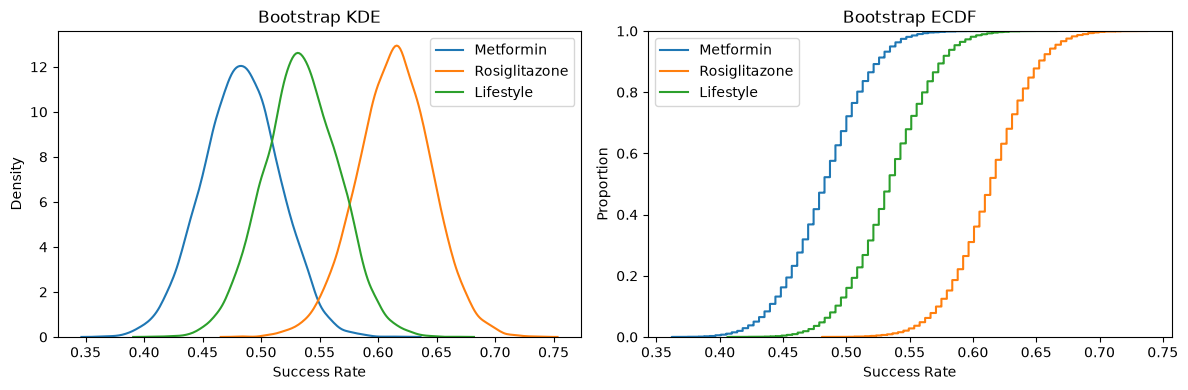

In [ ]:
## KDE and ECDF plots for the bootstrap results:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(outcome_met, ax=ax[0], label='Metformin')
sns.kdeplot(outcome_rosi, ax=ax[0], label='Rosiglitazone')
sns.kdeplot(outcome_lifestyle, ax=ax[0], label='Lifestyle')

ax[0].set_xlabel('Success Rate')
ax[0].set_title('Bootstrap KDE')
ax[0].legend()

## ECDF
sns.ecdfplot(outcome_met, ax=ax[1], label='Metformin')
sns.ecdfplot(outcome_rosi, ax=ax[1], label='Rosiglitazone')
sns.ecdfplot(outcome_lifestyle, ax=ax[1], label='Lifestyle')

ax[1].set_xlabel('Success Rate')
ax[1].set_title('Bootstrap ECDF')
ax[1].legend()

plt.tight_layout()
plt.show()


### Part2(3)
The KDE graphs shows the distribution of our 10,000 bootstrapped for all treatments. They are cenetered around differnt numbers, `Metformin`, for instance, is centred arounf `0.483`, `Rosiglitazone` is centered around `0.614`, and the `Lifestyle` is centered around `0.61.4`. Also, somewhat overlapes are visible between groups (green and blue- green and orange) which  indicates that some estimated bootstrapped success rates are plusible for more than one group.

On the other side, The position of ECDF results match with the KDE results(Rosi is the furthest right, Lifestyle in the middle, and Met furthest left). This indicates that the Rosiglitazone is estimated to produce higher success rate compare to two other groups in our bootstrapped samples. But still, we need to calculate the Confidance intervals befoere we decides which treate ment is better. 

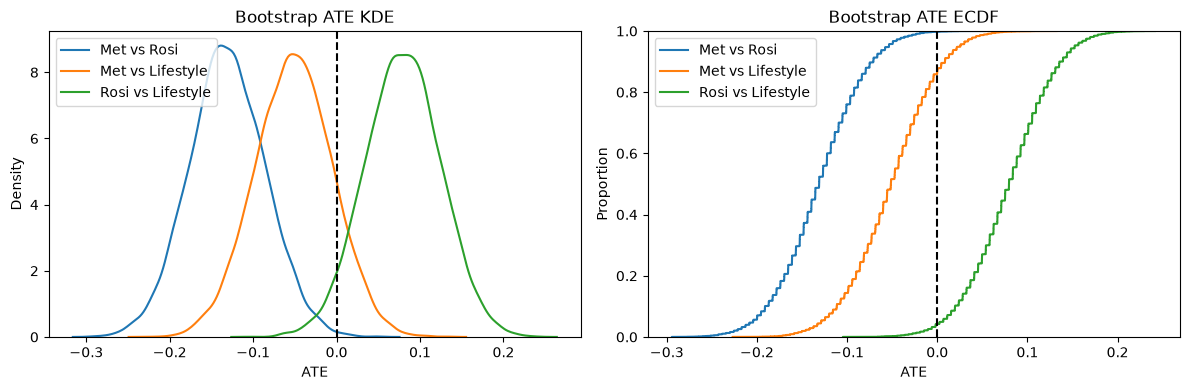

In [ ]:

## Part2(4) Bootstrap pairwise ATEs:
ate_met_rosi_boot = np.array(outcome_met) - np.array(outcome_rosi)
ate_met_lifestyle_boot = np.array(outcome_met) - np.array(outcome_lifestyle)
ate_rosi_lifestyle_boot = np.array(outcome_rosi) - np.array(outcome_lifestyle)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_met_rosi_boot, ax=ax[0], label='Met vs Rosi')
sns.kdeplot(ate_met_lifestyle_boot, ax=ax[0], label='Met vs Lifestyle')
sns.kdeplot(ate_rosi_lifestyle_boot, ax=ax[0], label='Rosi vs Lifestyle')

ax[0].axvline(0, color='black', linestyle='--')
ax[0].set_xlabel('ATE')
ax[0].set_title('Bootstrap ATE KDE')
ax[0].legend()

## ECDF
sns.ecdfplot(ate_met_rosi_boot, ax=ax[1], label='Met vs Rosi')
sns.ecdfplot(ate_met_lifestyle_boot, ax=ax[1], label='Met vs Lifestyle')
sns.ecdfplot(ate_rosi_lifestyle_boot, ax=ax[1], label='Rosi vs Lifestyle')

ax[1].axvline(0, color='black', linestyle='--')
ax[1].set_xlabel('ATE')
ax[1].set_title('Bootstrap ATE ECDF')
ax[1].legend()

plt.tight_layout()
plt.show()


In [26]:

## Part 2 (5): Bootstrap confidence intervals

# Metformin vs Rosiglitazone
ci90_met_rosi = np.quantile(ate_met_rosi_boot, [.05, .95])
ci95_met_rosi = np.quantile(ate_met_rosi_boot, [.025, .975])
ci99_met_rosi = np.quantile(ate_met_rosi_boot, [.005, .995])

# Metformin vs Lifestyle
ci90_met_lifestyle = np.quantile(ate_met_lifestyle_boot, [.05, .95])
ci95_met_lifestyle = np.quantile(ate_met_lifestyle_boot, [.025, .975])
ci99_met_lifestyle = np.quantile(ate_met_lifestyle_boot, [.005, .995])

# Rosiglitazone vs Lifestyle
ci90_rosi_lifestyle = np.quantile(ate_rosi_lifestyle_boot, [.05, .95])
ci95_rosi_lifestyle = np.quantile(ate_rosi_lifestyle_boot, [.025, .975])
ci99_rosi_lifestyle = np.quantile(ate_rosi_lifestyle_boot, [.005, .995])

## Print results
print('Metformin vs Rosiglitazone:')
print('90% CI:', np.round(ci90_met_rosi, 3))
print('95% CI:', np.round(ci95_met_rosi, 3))
print('99% CI:', np.round(ci99_met_rosi, 3))

print('\nMetformin vs Lifestyle:')
print('90% CI:', np.round(ci90_met_lifestyle, 3))
print('95% CI:', np.round(ci95_met_lifestyle, 3))
print('99% CI:', np.round(ci99_met_lifestyle, 3))

print('\nRosiglitazone vs Lifestyle:')
print('90% CI:', np.round(ci90_rosi_lifestyle, 3))
print('95% CI:', np.round(ci95_rosi_lifestyle, 3))
print('99% CI:', np.round(ci99_rosi_lifestyle, 3))


Metformin vs Rosiglitazone:
90% CI: [-0.204 -0.054]
95% CI: [-0.221 -0.041]
99% CI: [-0.247 -0.015]

Metformin vs Lifestyle:
90% CI: [-0.129  0.026]
95% CI: [-0.142  0.039]
99% CI: [-0.171  0.065]

Rosiglitazone vs Lifestyle:
90% CI: [0.007 0.152]
95% CI: [-0.01   0.169]
99% CI: [-0.04   0.195]


### Part2(5)
As you can see in the Confidance interval in all groups, the `Metformin vs Rosiglitazone` are ientirely negative and doesn't include `zero` in all of their confidance intervals (90%, 95%, 99%). Based on the Confidance, we reject the null hypothesis for this group at all three significance levels (1%, 5%, 10%). So, we can say that there is some statistical signifiance evidance that the `Rosiglitazone` has higher success rate than `Metformin`.

However at 90% CI, `Rosiglitazone vs. Lifestyle` is positive, but 95% and 99% intervals includes zero. So, we reject the null hypothesis wioth 10% confidance level, but we fail to reject the null hypothesis for the 5% and 1% confidance level. So, it give is weaker evidance that `Rosi` outperforms lifestyle. 

For `Metformin vs. Lifestyle`, all of its CI includes zero, so we fail to reject the null hypothesis. As a result we don't have enough evidance that Metformin treatement is better than Lifestyle or vise versa. 

Overall, we can say that the `Rosiglitazone` seems to be effective than `Metformin and Lifestyle`, based on the mean of its observed success rate `0.614 or 61.4%`. However, `Rosiglitazone` includes zero in its 95%, and 99% CI in Rosiglitazone vs Lifestyle group, so we cannot confidently conclude that it is better than life style at 5% and 1% significance level.

### Part2(6)

#### Study Overview
In this analysis, I tried to compare all three treatment methods for pre-diabetes to reduce the progression to full diabetes. These treatments are: metformin, rosiglitazone, and lifestyle adjustments which include diet and exercise. The dataset contains 699 obnservations for randomized controlled trail, an dthe outcomes are stored as success, or failure. I start by finding the average success rate of all three interventions, and find the Average Treatment Effect (ATE) all three groups. Then, I bootstrapped(resampled) 10,000 at teh same size as observed data with in each group in order to find the sampling variablity and find the confidance intervals for the pairwise Average Treatment Effects (ATEs).


The result from **the obvserved treatment** shows that `rosiglitazone` has the highest average success rate at 61.4%, `Life style` has 53.4%, and `metformin` with the 48.3 has the lowest average success rate. The estimated Average Treatment Effect (ATE) for `Metformin vs Rosiglitazone` is -0.131 which indicates that Rosiglitazone has 13.2 percentage point higher success rate than Metformin. `Metformin vs Lifestyle` has also -0.051 estimated Average Treatment Effect (ATE) meaning Life Style has 5.1 percentage point higher succes rate than Metformin. In the mean time,  `Rosiglitazone` has 8% percentage point higher succes rate than Lifestyle (ATE=0.08). Based on these results, `rosiglitazone` seems to be more perform better compare to Metformin and Lifestyle. 

The Average Treatment Effect (ATE) is estimated by taking the difference in the average success rates between two treatment groups:

$$
\widehat{ATE}_{A,B} = \bar{Y}_A - \bar{Y}_B
$$

Here $\bar{Y}_A$ and $\bar{Y}_B$ shows the observed success rates for treatments A and B.

**1. Metformin vs. Rosiglitazone**

$$
\widehat{ATE}_{met,rosi} = \bar{Y}_{met} - \bar{Y}_{rosi}
$$

$$
= 0.483 - 0.614 = \boxed{-0.131}
$$

**2. Metformin vs. Lifestyle**

$$
\widehat{ATE}_{met,lifestyle} = \bar{Y}_{met} - \bar{Y}_{lifestyle}
$$

$$
= 0.483 - 0.534 = \boxed{-0.051}
$$


**3. Rosiglitazone vs. Lifestyle**

$$
\widehat{ATE}_{rosi,lifestyle} = \bar{Y}_{rosi} - \bar{Y}_{lifestyle}
$$

$$
= 0.614 - 0.534 = \boxed{0.080}
$$

To undrestand the the uncertainity around these estimates, I bootstrapped 10,000 times within each treatment group and then calculated the 90%, 95%, and 99% confidence intervals for each pair wise treatement. The confidance intervals for `metformin versus rosiglitazone` showed that this group is statistically significant at 1%, 5%, and 10%  significance level because thier confidance interval didn't include zero. However at 90% CI, `Rosiglitazone vs Lifestyle` is also excludes zero, but 95% and 99% intervals includes zero. So, we reject the null hypothesis at the 10% significance level, but we fail to reject the null hypothesis for the 5% and 1% confidance level. So, it gives weaker evidance that `Rosiglitazone` outperforms lifestyle. But, the `Metformin vs Lifestyle` group includes zero in all of thier confidence intervals, so it is not statistically significance. 

1. **Metformin vs Rosiglitazone:**

    - 90% CI: [-0.204 -0.054]
    - 95% CI: [-0.221 -0.041]
    - 99% CI: [-0.247 -0.015]

2. **Metformin vs Lifestyle:**
    - 90% CI: [-0.129  0.026]
    - 95% CI: [-0.142  0.039]
    - 99% CI: [-0.171  0.065]

3. **Rosiglitazone vs Lifestyle:**

    - 90% CI: [0.007 0.152]
    - 95% CI: [-0.01   0.169]
    - 99% CI: [-0.04   0.195]


In conclusion, `Rosiglitazone` appears to be effective treatment for pre-diabetes to reduce the progression to full diabetes than `Metformin and Lifestyle` based on the mean of its observed success rate which is `0.614 or 61.4%`. The result showed that rosiglitazone perform better than metformin, and we have statistically significance evidance for it. But, `Rosiglitazone` includes zero in its 95%, and 99% CI in Rosiglitazone vs Lifestyle group, so its advantage over Life style is statiscally significance only at 10% significance level. Although, the result showed that lifestyle had a higher observed success rate than metformin, but the  difference between them was not statistically significant. Therefore, Rosiglitazone performs better based on the result, but we have to be careful and don;t generlize that. it better than all treatements. Since, this study has siome limition, and we have data about treatment safety, side effects, and other clinical considerations. So, these factors need to be evaluated before making a medical recommendation.